<a href="https://colab.research.google.com/github/SlepenkovaDaria/wine-classification/blob/main/wine_classification_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Классификация вин: kNN и Softmax-регрессия с нуля, CatBoost

## О проекте

**Цель проекта** - реализовать классические алгоритмы машинного обучения с нуля, исследовать особенности их работы и сравнить качество с современным ансамблевым методом CatBoost на задаче многоклассовой классификации.

В работе используется датасет **Wine** из библиотеки `sklearn.datasets`, содержащий 178 образцов вина, описанных 13 химическими характеристиками. Задача состоит в определении одного из трёх классов вина по его признакам.

В рамках проекта:

- Реализован алгоритм **kNN с нуля**, исследовано влияние масштабирования, метрики расстояния и количества соседей.
- Реализована **Softmax-регрессия с нуля** с градиентным спуском и L2-регуляризацией. Исследована сходимость и проведено сравнение с `sklearn.LogisticRegression`.
- Обучена модель **CatBoost**, подобраны гиперпараметры и проанализирована важность признаков.
- Проведено итоговое сравнение моделей по Accuracy, Macro F1 и матрицам ошибок.

**Инструменты:** Python, NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn, CatBoost.

In [1]:
%pip install catboost -q

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, log_loss, f1_score
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier
wine = load_wine()

In [3]:
print(wine.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])


In [4]:
print(wine.data.shape)
print(wine.target.shape)

(178, 13)
(178,)


In [5]:
df = pd.DataFrame(wine.data, columns = wine.feature_names)
df["target"] = wine.target
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [7]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


In [8]:
df["target"].value_counts()

,count
target,
1,71
0,59
2,48


Для визуального анализа взаимосвязей между признаками построим матрицу диаграмм рассеяния.

Поскольку датасет содержит 13 признаков, полная матрица будет слишком громоздкой. Ограничимся пятью признаками: `alcohol`, `malic_acid`, `flavanoids`, `color_intensity` и `proline`.

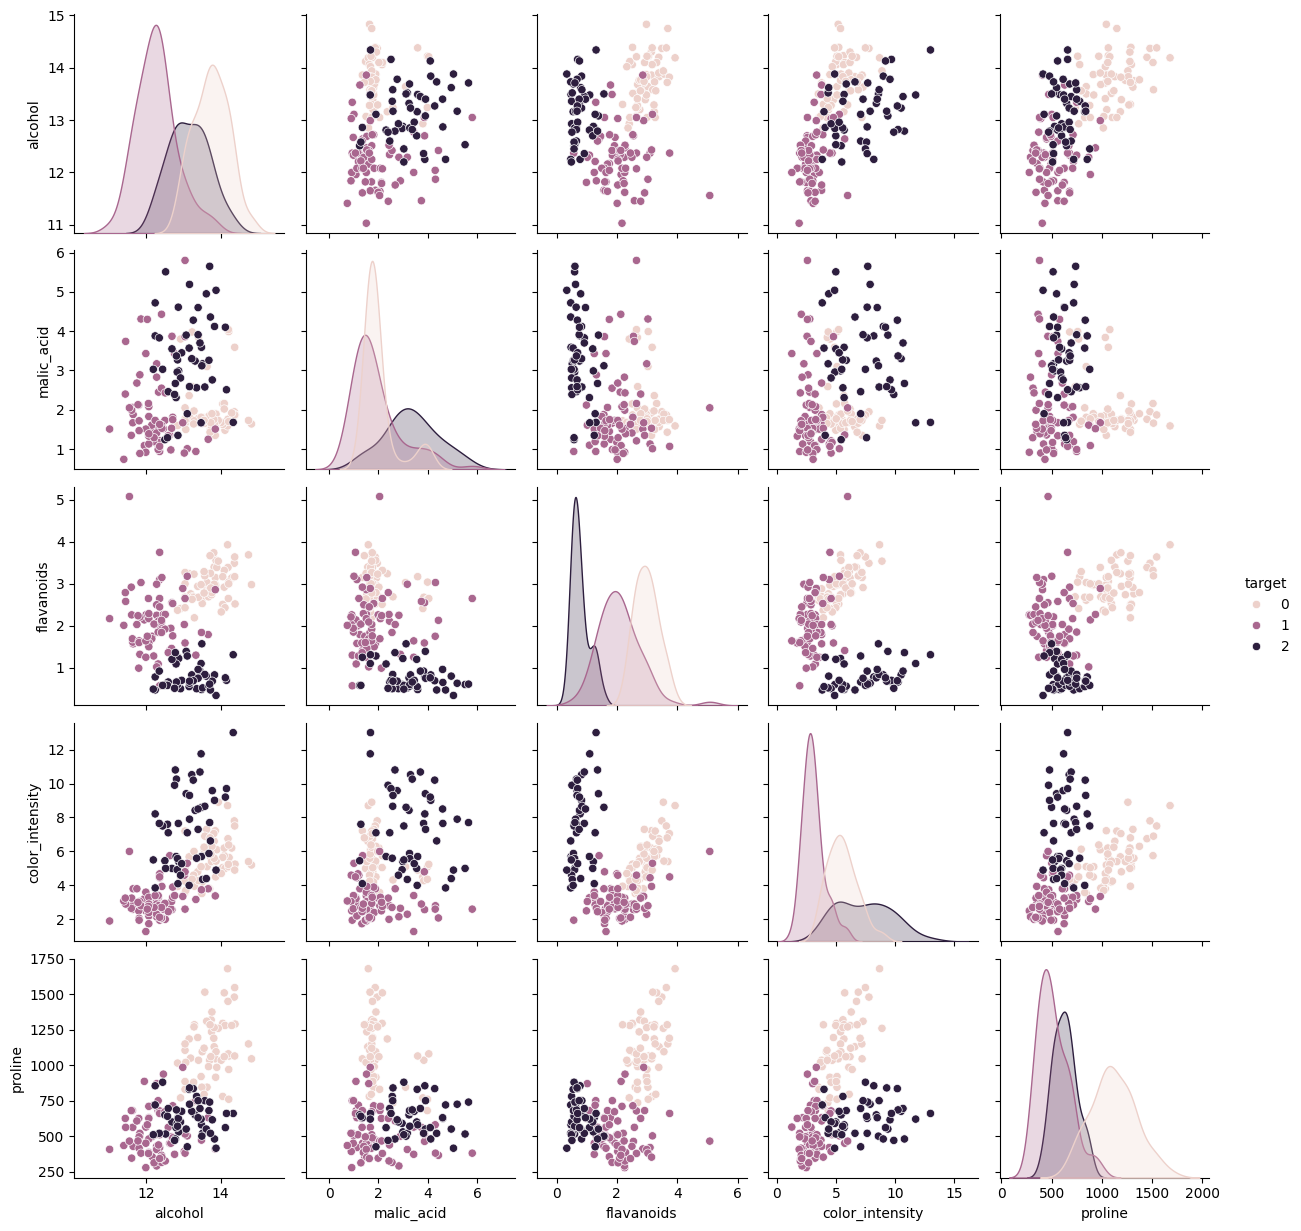

In [9]:
features = ['alcohol', 'malic_acid', 'flavanoids', 'color_intensity', 'proline']
sns.pairplot(df, vars = features, hue = "target")
plt.show()

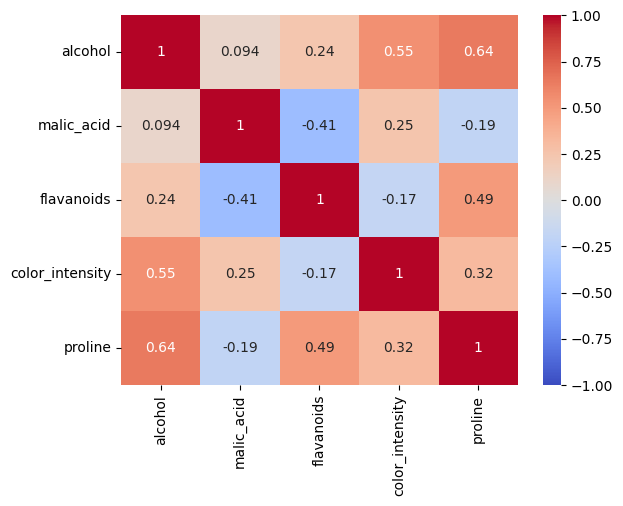

In [10]:
sns.heatmap(df[features].corr(), annot = True, cmap = "coolwarm", vmin = -1, vmax = 1)
plt.show()

In [11]:
X = df.drop(columns = "target")
y = df["target"]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size = 0.4, random_state = 42, stratify = y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size = 0.5, random_state = 42, stratify = y_temp)

## kNN

Поскольку kNN основан на вычислении расстояний между объектами, признаки с большими числовыми значениями могут непропорционально сильно влиять на результат.

Для устранения этого эффекта применим стандартизацию с помощью `StandardScaler`. Параметры масштабирования вычисляются только на обучающей выборке.

In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [13]:
def knn_predict(X_train, y_train, X_val, k, metric):
  predictions = []

  for x in X_val:

    if metric == "euclidean":
      distances = np.sqrt(np.sum((X_train - x) ** 2, axis = 1))

    elif metric == "manhattan":
      distances = np.sum(np.abs(X_train - x), axis = 1)

    elif metric == "chebyshev":
      distances = np.max(np.abs(X_train - x), axis = 1)

    nearest_idx = np.argsort(distances)[:k]
    nearest_labels = y_train.iloc[nearest_idx]
    counted_labels = np.bincount(nearest_labels)
    predicted_class = np.argmax(counted_labels)
    predictions.append(predicted_class)

  return np.array(predictions)

In [14]:
k_values = range(1, 26)
accuracies_euclidean = []
accuracies_manhattan = []
accuracies_chebyshev = []

for k in k_values:
  y_pred = knn_predict(X_train_scaled, y_train, X_val_scaled, k, "euclidean")
  accuracy = np.mean(y_pred == y_val.to_numpy())
  accuracies_euclidean.append(accuracy)

  y_pred = knn_predict(X_train_scaled, y_train, X_val_scaled, k, "manhattan")
  accuracy = np.mean(y_pred == y_val.to_numpy())
  accuracies_manhattan.append(accuracy)

  y_pred = knn_predict(X_train_scaled, y_train, X_val_scaled, k, "chebyshev")
  accuracy = np.mean(y_pred == y_val.to_numpy())
  accuracies_chebyshev.append(accuracy)

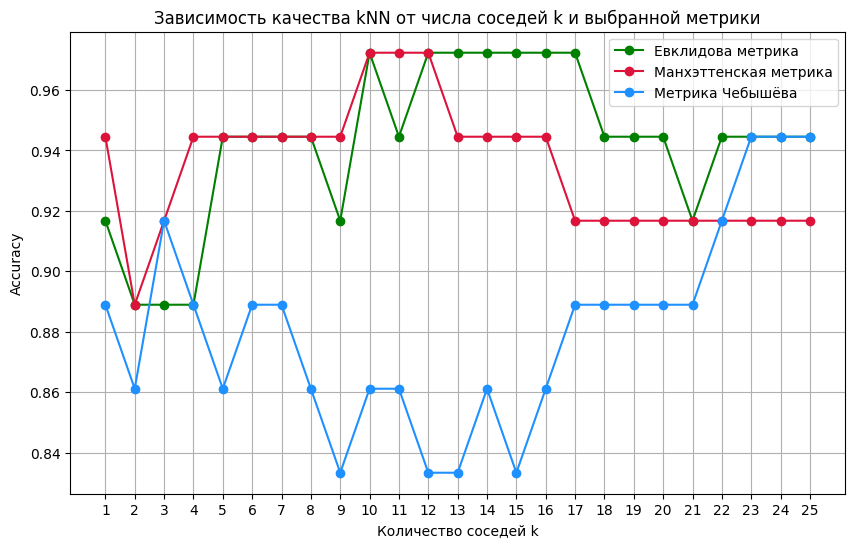

In [15]:
plt.figure(figsize = (10, 6))

plt.plot(k_values, accuracies_euclidean, marker = "o", color = "green", label = "Евклидова метрика")
plt.plot(k_values, accuracies_manhattan, marker = "o", color = "crimson", label = "Манхэттенская метрика")
plt.plot(k_values, accuracies_chebyshev, marker = "o", color = "dodgerblue", label = "Метрика Чебышёва")

plt.xlabel("Количество соседей k")
plt.ylabel("Accuracy")
plt.title("Зависимость качества kNN от числа соседей k и выбранной метрики")
plt.xticks(k_values)
plt.grid()
plt.legend()

plt.show()

In [16]:
results = {"euclidean": accuracies_euclidean, "manhattan": accuracies_manhattan, "chebyshev": accuracies_chebyshev}

best_metric = max(results, key = lambda m: max(results[m]))
best_idx = np.argmax(results[best_metric])
best_k = list(k_values)[best_idx]
best_accuracy = results[best_metric][best_idx]

print(f"Лучшая метрика: {best_metric}")
print(f"Лучшее k: {best_k}")
print(f"Validation Accuracy: {best_accuracy:.4f}")

Лучшая метрика: euclidean
Лучшее k: 10
Validation Accuracy: 0.9722


Сравним качество классификации с использованием стандартизированных и исходных признаков. Это позволит оценить, насколько масштабирование влияет на работу алгоритма.

In [17]:
raw_accuracies = []

for k in k_values:
  y_pred_raw = knn_predict(X_train.to_numpy(), y_train, X_val.to_numpy(), k, "euclidean")
  raw_accuracy = np.mean(y_pred_raw == y_val.to_numpy())
  raw_accuracies.append(raw_accuracy)

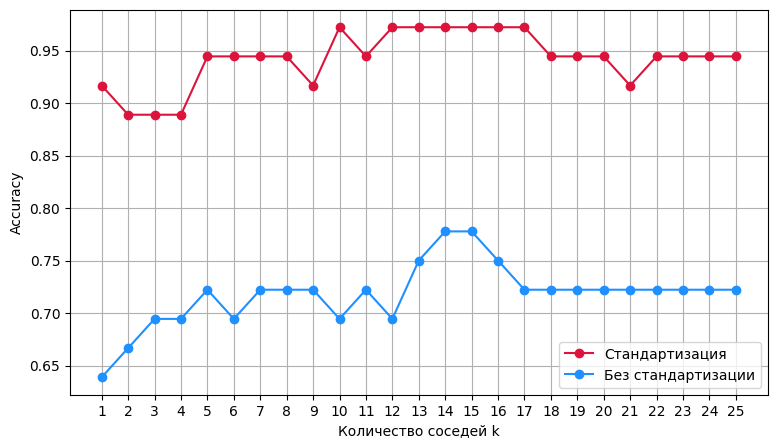

In [18]:
plt.figure(figsize = (9, 5))

plt.plot(k_values, accuracies_euclidean, marker = "o", color = "crimson", label = "Стандартизация")
plt.plot(k_values, raw_accuracies, marker = "o", color = "dodgerblue", label = "Без стандартизации")

plt.xlabel("Количество соседей k")
plt.ylabel("Accuracy")
plt.legend()
plt.xticks(k_values)
plt.grid()

plt.show()

## Логистическая регрессия

$s_k = \sum_{j=1}^{13} x_j w_{jk} + b_k$

$x_j$ — значение признака;

$w_{jk}$ — вес признака j для класса k;

$b_k$ — свободный член для класса k;

$s_k$ — оценка принадлежности объекта к классу k.

$P(y=k\mid x)= \frac{e^{s_k}}{\sum_{c=0}^{2}e^{s_c}}.$

$L_i=-\ln P(y=y_i\mid x_i).$

$$\boxed{L(W,b)=-\frac{1}{N}\sum_{i=1}^{N}\ln p_{i,y_i}}$$

Градиентный спуск обновляет параметры по формулам:
\begin{aligned}
W_{\text{new}}&=W-\eta\nabla_W L,\\
b_{\text{new}}&=b-\eta\nabla_b L.
\end{aligned}

Здесь $\eta$ — скорость обучения (learning rate).

Для Softmax в сочетании с кросс-энтропией справедлива формула:
$\frac{\partial L}{\partial s_{ik}}=\frac{1}{N}(p_{ik}-\mathbb{1}[y_i=k]).$

1. $\frac{\partial L}{\partial w_{jk}} =
\sum_{i=1}^{N}
\frac{\partial L}{\partial s_{ik}}
\frac{\partial s_{ik}}{\partial w_{jk}}$, но $\frac{\partial s_{ik}}{\partial w_{jk}}=x_{ij}$,
следовательно

$$
\boxed{
\frac{\partial L}{\partial w_{jk}}
=
\frac1N\sum_{i=1}^{N}
x_{ij}(p_{ik}-\mathbb{1}[y_i=k])
}
$$

$$\boxed{\nabla_W L=X^T(P-Y)/N=X^TdS}$$

2. $\frac{\partial s_{ik}}{\partial b_k}=1$, следовательно

$$
\boxed{
\frac{\partial L}{\partial b_k}
=
\frac1N\sum_{i=1}^{N}
(p_{ik}-\mathbb{1}[y_i=k])
}
$$

Попробуем реализовать L2-регуляризацию

$$
\boxed{
L(W,b)=L_{\mathrm{CE}}(W,b)
+\frac{\lambda}{2}\sum_{j=1}^{13}\sum_{k=0}^{2}w_{jk}^{2}
}
$$

$\lambda\geq0$ — коэффициент регуляризации

$\frac{\partial}{\partial W}
\left(\frac{\lambda}{2}\|W\|_F^2\right)
=\lambda W$, следовательно

$$
\boxed{\nabla_W L=X^TdS+\lambda W.}
$$

In [19]:
def log_regression_reg(X_train_scaled, y_train, X_val_scaled, y_val, eta, n_iterations, reg_lambda = 0):
  n_features = X_train_scaled.shape[1]
  n_classes = 3
  rng = np.random.default_rng(42)

  W = rng.normal(0, 0.01, size = (n_features, n_classes))
  b = np.zeros(n_classes)
  train_loss_history = []
  val_loss_history = []

  y_true_train = y_train.to_numpy()
  y_true_val = y_val.to_numpy()
  n_samples = len(y_true_train)
  Y = np.eye(n_classes)[y_true_train]

  for i in range(n_iterations):
      train_scores = X_train_scaled @ W + b
      train_exp_scores = np.exp(train_scores - np.max(train_scores, axis = 1, keepdims = True))
      train_probs = train_exp_scores / np.sum(train_exp_scores, axis = 1, keepdims = True)

      train_true_probs = train_probs[np.arange(n_samples), y_true_train]
      train_loss = -np.mean(np.log(np.maximum(train_true_probs, 1e-15))) + reg_lambda / 2 * np.sum(W ** 2)
      train_loss_history.append(train_loss)

      val_scores = X_val_scaled @ W + b
      val_exp_scores = np.exp(val_scores - np.max(val_scores, axis = 1, keepdims = True))
      val_probs = val_exp_scores / np.sum(val_exp_scores, axis = 1, keepdims = True)

      val_true_probs = val_probs[np.arange(len(y_true_val)), y_true_val]
      val_loss = -np.mean(np.log(np.maximum(val_true_probs, 1e-15)))
      val_loss_history.append(val_loss)

      dS = (train_probs - Y) / n_samples
      dW = X_train_scaled.T @ dS + reg_lambda * W
      db = np.sum(dS, axis = 0)

      W -= eta * dW
      b -= eta * db

  return W, b, train_loss_history, val_loss_history

In [20]:
_, _, small_train_loss, small_val_loss = log_regression_reg(X_train_scaled, y_train, X_val_scaled, y_val, 0.01, 500)
_, _, middle_train_loss, middle_val_loss = log_regression_reg(X_train_scaled, y_train, X_val_scaled, y_val, 0.1, 500)
_, _, huge_train_loss, huge_val_loss = log_regression_reg(X_train_scaled, y_train, X_val_scaled, y_val, 0.5, 500)

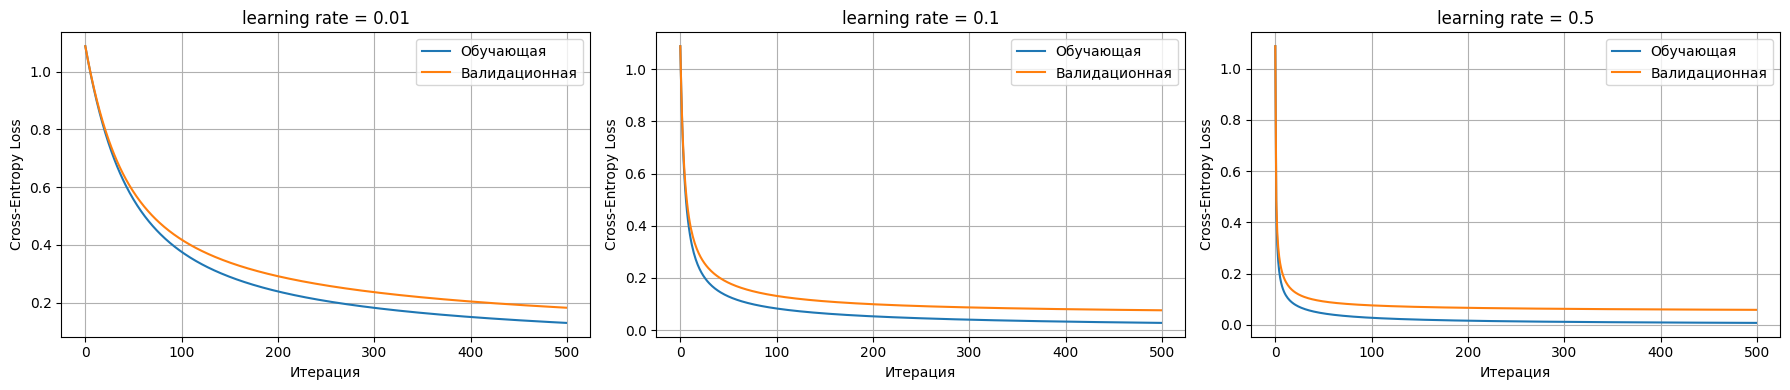

In [21]:
plt.figure(figsize = (18, 4))

plt.subplot(1, 3, 1)
plt.plot(small_train_loss, label = "Обучающая")
plt.plot(small_val_loss, label = "Валидационная")
plt.xlabel("Итерация")
plt.ylabel("Cross-Entropy Loss")
plt.title("learning rate = 0.01")
plt.legend()
plt.grid()

plt.subplot(1, 3, 2)
plt.plot(middle_train_loss, label = "Обучающая")
plt.plot(middle_val_loss, label = "Валидационная")
plt.xlabel("Итерация")
plt.ylabel("Cross-Entropy Loss")
plt.title("learning rate = 0.1")
plt.legend()
plt.grid()

plt.subplot(1, 3, 3)
plt.plot(huge_train_loss, label = "Обучающая")
plt.plot(huge_val_loss, label = "Валидационная")
plt.xlabel("Итерация")
plt.ylabel("Cross-Entropy Loss")
plt.title("learning rate = 0.5")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [22]:
W, b, train_loss, val_loss = log_regression_reg(X_train_scaled, y_train, X_val_scaled, y_val, 0.5, 500)

val_scores = X_val_scaled @ W + b
y_val_pred = np.argmax(val_scores, axis = 1)
val_accuracy = np.mean(y_val_pred == y_val.to_numpy())

print(f"Validation accuracy: {round(val_accuracy, 4)}")

Validation accuracy: 0.9722


In [23]:
_, _, train_0, val_0 = log_regression_reg(X_train_scaled, y_train, X_val_scaled, y_val, 0.5, 500, 0)
_, _, train_001, val_001 = log_regression_reg(X_train_scaled, y_train, X_val_scaled, y_val, 0.5, 500, 0.001)
_, _, train_01, val_01 = log_regression_reg(X_train_scaled, y_train, X_val_scaled, y_val, 0.5, 500, 0.01)
_, _, train_1, val_1 = log_regression_reg(X_train_scaled, y_train, X_val_scaled, y_val, 0.5, 500, 0.1)

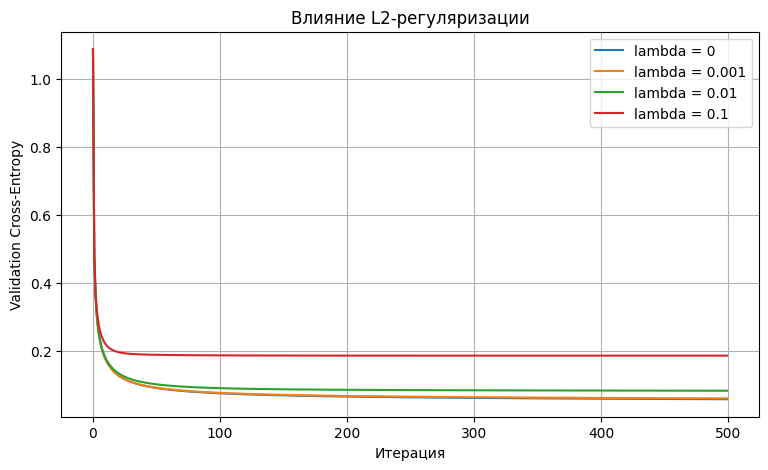

In [24]:
plt.figure(figsize = (9, 5))

plt.plot(val_0, label = "lambda = 0")
plt.plot(val_001, label = "lambda = 0.001")
plt.plot(val_01, label = "lambda = 0.01")
plt.plot(val_1, label = "lambda = 0.1")

plt.xlabel("Итерация")
plt.ylabel("Validation Cross-Entropy")
plt.title("Влияние L2-регуляризации")
plt.legend()
plt.grid()
plt.show()

In [25]:
lambdas = [0, 0.001, 0.01, 0.1]
models = {}

for lam in lambdas:
  W, b, train_loss, val_loss = log_regression_reg(X_train_scaled, y_train, X_val_scaled, y_val, 0.5, 500, lam)
  models[lam] = (W, b)

In [26]:
def evaluate_model(X, y, W, b):
  y_true = y.to_numpy()
  scores = X @ W + b

  exp_scores = np.exp(scores - np.max(scores, axis = 1, keepdims = True))
  probs = exp_scores / np.sum(exp_scores, axis = 1, keepdims = True)

  true_probs = probs[np.arange(len(y_true)), y_true]

  CE = -np.mean(np.log(np.maximum(true_probs, 1e-15)))

  y_pred = np.argmax(probs, axis = 1)
  accuracy = np.mean(y_pred == y_true)
  weight_norm = np.linalg.norm(W)

  return CE, accuracy, weight_norm

In [27]:
results = []

for lam, (W, b) in models.items():
  CE, accuracy, weight_norm = evaluate_model(X_val_scaled, y_val, W, b)
  results.append({"lambda": lam, "Cross-Entropy": CE, "Accuracy": accuracy, "Weight norm": weight_norm})

results_df = pd.DataFrame(results)
results_df.round(4)

,lambda,Cross-Entropy,Accuracy,Weight norm
0,0.000,0.0583,0.9722,5.1683
1,0.001,0.0608,0.9722,4.6434
2,0.010,0.0833,0.9722,2.9932
3,0.100,0.1865,0.9722,1.5726


In [28]:
sk_model = LogisticRegression(C = np.inf, solver = "lbfgs", max_iter = 10000, tol = 1e-10)
sk_model.fit(X_train_scaled, y_train)

LogisticRegression(C=inf, max_iter=10000, tol=1e-10)

In [29]:
W, b = models[0]

ce_custom, acc_custom, _ = evaluate_model(X_val_scaled, y_val, W, b)

ce_sklearn = log_loss(y_val, sk_model.predict_proba(X_val_scaled))
acc_sklearn = sk_model.score(X_val_scaled, y_val)

comparison = pd.DataFrame({"Model": ["Custom Softmax", "Sklearn LogisticRegression"], "Accuracy": [acc_custom, acc_sklearn], "Cross-Entropy": [ce_custom, ce_sklearn]})
comparison.round(4)

,Model,Accuracy,Cross-Entropy
0,Custom Softmax,0.9722,0.0583
1,Sklearn LogisticRegression,0.9444,0.0496


## Градиентный бустинг

In [30]:
cb_model = CatBoostClassifier(iterations = 300, depth = 4, learning_rate = 0.05, loss_function = "MultiClass", random_seed = 42, verbose = False)
cb_model.fit(X_train, y_train)

y_pred_cb = cb_model.predict(X_val).ravel()
probs_cb = cb_model.predict_proba(X_val)

print(f"Accuracy: {np.round(accuracy_score(y_val, y_pred_cb), 4)}")
print(f"Cross-Entropy: {np.round(log_loss(y_val, probs_cb), 4)}")

Accuracy: 0.9722
Cross-Entropy: 0.1111


In [31]:
cb_results = []

for depth in [3, 4, 5]:
  for iterations in [100, 300]:
    model = CatBoostClassifier(iterations = iterations, depth = depth, learning_rate = 0.05, loss_function = "MultiClass", random_seed = 42, verbose = False)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_val).ravel()
    probs = model.predict_proba(X_val)

    cb_results.append({"depth": depth, "iterations": iterations, "Accuracy": accuracy_score(y_val, y_pred), "Cross-Entropy": log_loss(y_val, probs)})

cb_results_df = pd.DataFrame(cb_results)
cb_results_df.sort_values("Cross-Entropy").round(4)

,depth,iterations,Accuracy,Cross-Entropy
1,3,300,0.9722,0.1012
3,4,300,0.9722,0.1111
5,5,300,0.9722,0.1323
2,4,100,0.9722,0.1931
0,3,100,0.9444,0.1938
4,5,100,0.9444,0.2307


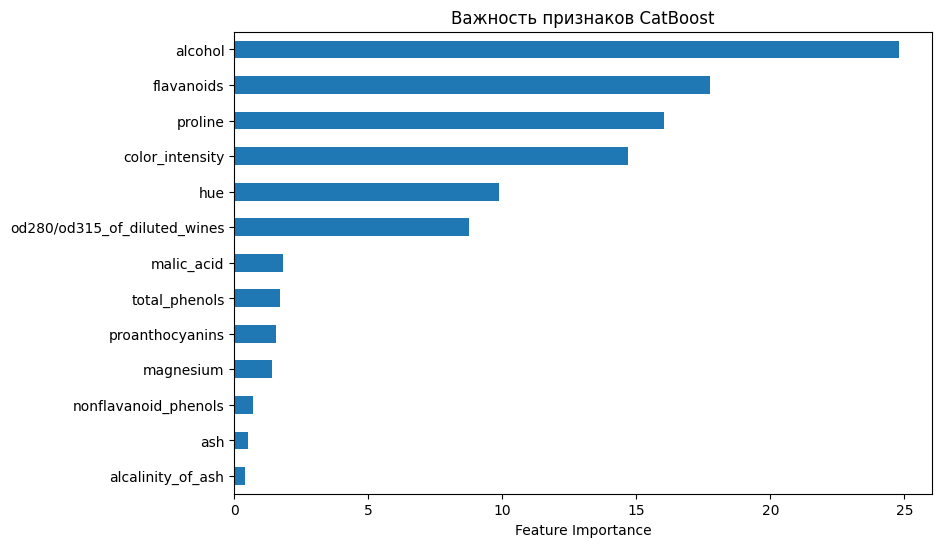

In [32]:
best_row = cb_results_df.loc[cb_results_df["Cross-Entropy"].idxmin()]

cb_model = CatBoostClassifier(iterations = int(best_row["iterations"]), depth = int(best_row["depth"]),
    learning_rate = 0.05, loss_function = "MultiClass", random_seed = 42, verbose = False)

cb_model.fit(X_train, y_train)

importance = pd.Series(cb_model.feature_importances_, index = X_train.columns).sort_values()
importance.plot(kind = "barh", figsize = (9, 6))

plt.xlabel("Feature Importance")
plt.title("Важность признаков CatBoost")
plt.show()

## Сравнение моделей на тестовой выборке

In [33]:
X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])

scaler_final = StandardScaler()

X_trainval_scaled = scaler_final.fit_transform(X_trainval)
X_test_scaled_final = scaler_final.transform(X_test)

In [34]:
y_pred_knn = knn_predict(X_trainval_scaled, y_trainval, X_test_scaled_final, k = best_k, metric = best_metric)

W_final, b_final, _, _ = log_regression_reg(X_trainval_scaled, y_trainval, X_trainval_scaled, y_trainval, eta = 0.5, n_iterations = 500, reg_lambda = 0)
scores = X_test_scaled_final @ W_final + b_final
y_pred_softmax = np.argmax(scores, axis = 1)

cb_final = CatBoostClassifier(iterations = int(best_row["iterations"]), depth = int(best_row["depth"]), learning_rate = 0.05,
    loss_function = "MultiClass", random_seed = 42, verbose = False)
cb_final.fit(X_trainval, y_trainval)
y_pred_cb = cb_final.predict(X_test).ravel()

In [35]:
predictions = {"kNN": y_pred_knn, "Softmax": y_pred_softmax, "CatBoost": y_pred_cb}
final_results = []

for name, y_pred in predictions.items():
    final_results.append({"Model": name, "Accuracy": accuracy_score(y_test, y_pred), "Macro F1": f1_score(y_test, y_pred, average = "macro")})

final_df = pd.DataFrame(final_results)
final_df.round(4)

,Model,Accuracy,Macro F1
0,kNN,0.9444,0.9453
1,Softmax,0.9722,0.9710
2,CatBoost,1.0000,1.0000


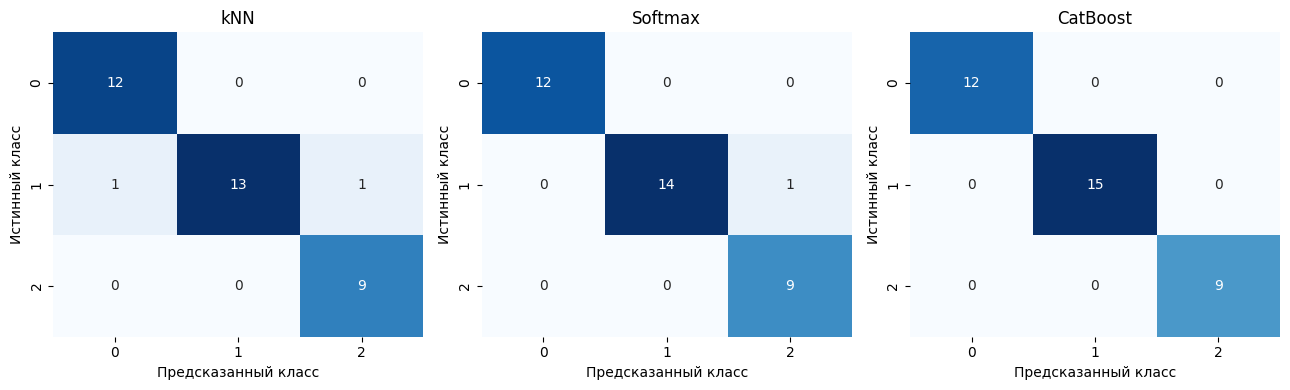

In [36]:
fig, axes = plt.subplots(1, 3, figsize = (13, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels = [0, 1, 2])
    sns.heatmap(cm, annot = True, fmt = "d", cmap = "Blues", cbar = False, ax = ax)

    ax.set_title(name)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")

plt.tight_layout()
plt.show()

## Выводы по результатам эксперимента

В рамках проекта реализованы с нуля два алгоритма многоклассовой классификации - kNN и Softmax-регрессия с градиентным спуском и L2-регуляризацией. Дополнительно обучена ансамблевая модель CatBoost.

**Основные результаты:**

- Исследовано влияние масштабирования признаков и выбора метрики расстояния на качество kNN.
- Изучена сходимость градиентного спуска при различных learning rate и влияние L2-регуляризации.
- Проведено сравнение собственной Softmax-регрессии с реализацией из sklearn.
- Подобраны гиперпараметры CatBoost и проанализирована относительная важность признаков.
- На тестовой выборке CatBoost достиг Accuracy = 1.0000 и Macro F1 = 1.0000, Softmax-регрессия - 0.9722 и 0.9710, kNN — 0.9444 и 0.9453 соответственно.

**Итог:** CatBoost показал наилучшее качество на тестовой выборке. При этом собственные реализации классических алгоритмов продемонстрировали сопоставимые результаты.

Из-за небольшого размера датасета (178 объектов, из которых 36 использовались для тестирования) полученные оценки качества следует интерпретировать с осторожностью.